# Hands-On Module 4: Titanic Survival Classification
## Google Developer Group, Bandung Institute of Technology

**Dataset:** `sns.load_dataset('titanic')`
**Tools:** NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn

Pipeline: EDA → preprocessing → train-test split → Logistic Regression, KNN, Decision Tree → evaluation → model comparison, plus Bonus 1–3.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve)

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)

---
## Stage 1: Data Preparation and EDA

### 1.1 Load and inspect missing values

In [2]:
df = sns.load_dataset("titanic")
print("Shape:", df.shape)
missing = df.isna().sum()
pd.DataFrame({"missing": missing, "pct": (missing / len(df) * 100).round(1)})[missing > 0]

Shape: (891, 15)


,missing,pct
age,177,19.9
embarked,2,0.2
deck,688,77.2
embark_town,2,0.2


**Observation:** Three columns have gaps: `deck` (688 missing, 77.2%), `age` (177, 19.9%) and `embarked` (2, 0.2%; `embark_town` mirrors it).

**Decisions:**
- **Drop `deck`.** More than three quarters is missing, so any imputation would be mostly invented values. The remaining 23% is also not a random sample (cabin records mostly survive for first-class passengers).
- **Drop the 2 rows without `embarked`.** Losing 2 of 891 rows (0.2%) costs nothing, and guessing a port for them would add noise.
- **Impute `age` with the median per `pclass` × `sex`.** 20% is too much to drop, and age is one of the strongest signals. A plain overall median would ignore that age differs by group (first-class passengers are older than third-class ones). The median is robust to the right-skewed age distribution.
- **Leakage guard:** the imputation medians are computed on the **training set only** (the split is done at the end of Stage 1, see 1.4) and then applied to both train and test. Computing them on the whole dataset first would let test information leak into training.

In [3]:
df = df.drop(columns=["deck"])
df = df.dropna(subset=["embarked"]).reset_index(drop=True)
print("Shape after dropping deck and 2 rows without embarked:", df.shape)

Shape after dropping deck and 2 rows without embarked: (889, 14)


### 1.2 Drop redundant columns

**Why each column is dropped:**

| Column | Reason |
|---|---|
| `alive` | A text copy of the target (`yes`/`no`). Keeping it would be **target leakage**: a perfect predictor. |
| `class` | Text copy of `pclass`. |
| `embark_town` | Text copy of `embarked`. |
| `who` | Derived from `sex` and `age` (man / woman / child). |
| `adult_male` | Derived from `sex` and `age` (male and age ≥ 16). |
| `alone` | Derived from `sibsp` and `parch` (both zero). |

The last three are not in the task's example list, but they are exact functions of columns we keep, so they add no information. They would also introduce multicollinearity that makes the logistic coefficients hard to read.

In [4]:
df = df.drop(columns=["alive", "class", "embark_town", "who", "adult_male", "alone"])
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


### 1.3 Survival rate by `sex` and `pclass`

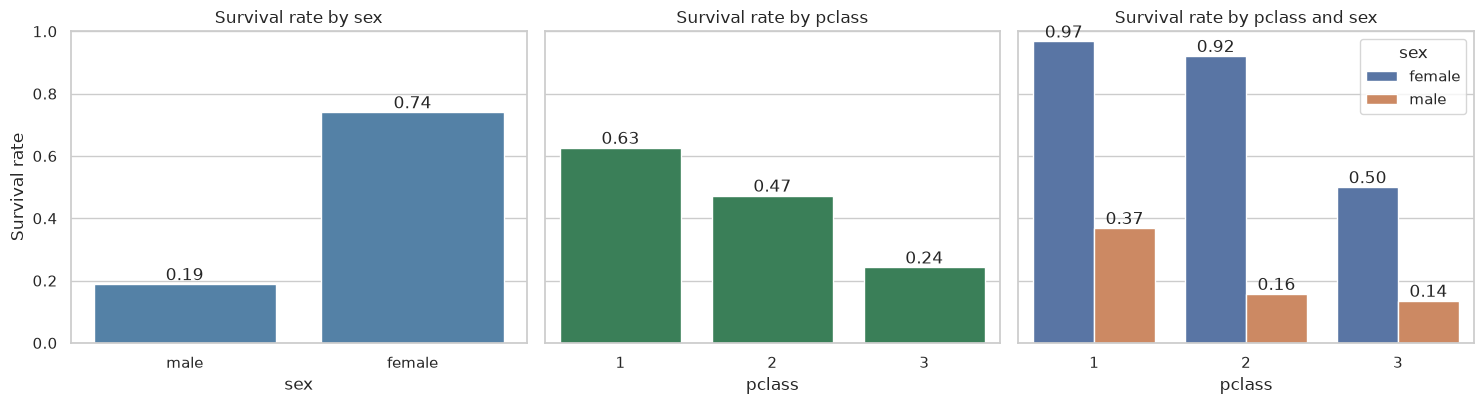

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
sns.barplot(data=df, x="sex", y="survived", ax=axes[0], color="steelblue", errorbar=None)
sns.barplot(data=df, x="pclass", y="survived", ax=axes[1], color="seagreen", errorbar=None)
sns.barplot(data=df, x="pclass", y="survived", hue="sex", ax=axes[2], errorbar=None)
for ax, t in zip(axes, ["by sex", "by pclass", "by pclass and sex"]):
    ax.set_title(f"Survival rate {t}"); ax.set_ylim(0, 1)
axes[0].set_ylabel("Survival rate")
for ax in axes:
    for c in ax.containers: ax.bar_label(c, fmt="%.2f")
plt.tight_layout(); plt.show()

**Pattern:** Sex and class both matter a lot, and they interact.
- Women survived at 74.0%, men at 18.9%.
- First class 62.6%, second 47.3%, third 24.2%.
- Combined: first- and second-class women survived at 97% and 92%, third-class women at 50%, and men only 37% (first class), 16% (second) and 13.5% (third).

This matches the "women and children first" rule, with a clear class advantage on top of it.

### 1.4 Class balance, encoding and split

                 count  share
survived                     
did not survive    549  0.618
survived           340  0.382


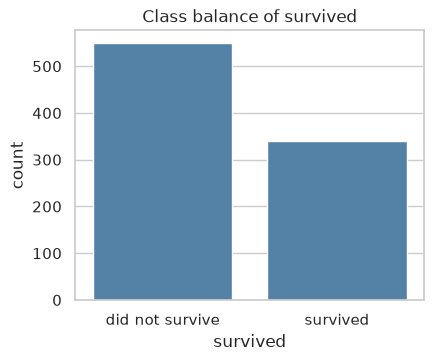

In [6]:
balance = df["survived"].value_counts().rename({0: "did not survive", 1: "survived"})
print(pd.DataFrame({"count": balance, "share": (balance / len(df)).round(3)}))
plt.figure(figsize=(4.5, 3.5))
sns.countplot(data=df, x="survived", color="steelblue")
plt.xticks([0, 1], ["did not survive", "survived"]); plt.title("Class balance of survived")
plt.show()

**Class balance:** 61.8% did not survive and 38.2% survived (roughly 8:5). That is a mild imbalance, not a severe one like fraud detection. The consequence: always predicting "died" already scores 61.8% accuracy, so **accuracy must be read against this baseline**, and I report precision, recall and F1 alongside it. The split uses `stratify=y` so both sets keep the same 38% survival share (0.383 train, 0.382 test).

**Encoding:** `sex` becomes a binary column (1 = female) because it has two values. `embarked` has three ports (S, C, Q) with no order, so it is one-hot encoded with `drop_first=True` (Southampton is the reference level), which avoids a redundant column.

In [7]:
# sex -> binary (1 = female); embarked -> one-hot (S is the dropped reference level)
df["sex"] = (df["sex"] == "female").astype(int)
df = pd.get_dummies(df, columns=["embarked"], drop_first=True, dtype=int)

X = df.drop(columns="survived")
y = df["survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# age imputation: median per (pclass, sex), computed on the TRAINING set only
age_median = X_train.groupby(["pclass", "sex"])["age"].median()
print(age_median)
def impute_age(D):
    D = D.copy()
    fill = D.apply(lambda r: age_median[(r["pclass"], r["sex"])], axis=1)
    D["age"] = D["age"].fillna(fill)
    return D
X_train, X_test = impute_age(X_train), impute_age(X_test)
print("Missing age after imputation  train:", X_train.age.isna().sum(), " test:", X_test.age.isna().sum())
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Survival share  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

pclass  sex
1       0      40.0
        1      33.0
2       0      30.0
        1      29.5
3       0      25.5
        1      22.0
Name: age, dtype: float64
Missing age after imputation  train: 0  test: 0
Train: (711, 8)  Test: (178, 8)
Survival share  train: 0.383  test: 0.382


The split is 80/20 with `random_state=42` and `stratify=y` (so Stage 2.1 is done here, a step earlier than the task order, to keep the age imputation leak-free).

---
## Stage 2: Logistic Regression

### 2.1 Train-test split
Done at the end of Stage 1 (711 train / 178 test, stratified, `random_state=42`).

### 2.2 Pipeline `StandardScaler` + `LogisticRegression`

accuracy     0.8258
precision    0.8136
recall       0.7059
f1           0.7559
auc          0.8592


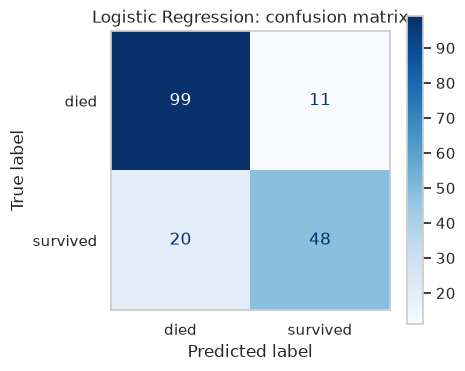

In [8]:
lr = Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression())])
lr.fit(X_train, y_train)

def metrics_row(name, model, X_te=None, y_te=None):
    X_te = X_test if X_te is None else X_te
    y_te = y_test if y_te is None else y_te
    pred = model.predict(X_te); proba = model.predict_proba(X_te)[:, 1]
    return dict(model=name,
                accuracy=accuracy_score(y_te, pred), precision=precision_score(y_te, pred),
                recall=recall_score(y_te, pred), f1=f1_score(y_te, pred), auc=roc_auc_score(y_te, proba))

print(pd.Series(metrics_row("Logistic Regression", lr)).drop("model").round(4).to_string())
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_estimator(lr, X_test, y_test, display_labels=["died", "survived"], cmap="Blues", ax=ax)
ax.set_title("Logistic Regression: confusion matrix"); ax.grid(False)
plt.show()

**Interpretation:** accuracy 0.826 (against a 0.618 baseline), precision 0.814, recall 0.706, F1 0.756, AUC 0.859. The confusion matrix: 99 died-and-predicted-died, 11 died-but-predicted-survived, 20 survived-but-predicted-died, 48 correct survivors.

For the *survived* class, the model is cautious: when it says "survived" it is right 81% of the time, but it finds only 71% of the real survivors (20 of 68 missed). It is better at recognising who died (90% of the 110 deaths found).

### 2.3 Coefficients

,coef (log-odds),odds ratio
sex,1.2518,3.4965
fare,0.1128,1.1194
embarked_Q,0.0771,1.0801
parch,-0.0790,0.9241
embarked_S,-0.1301,0.8780
sibsp,-0.2832,0.7533
age,-0.5369,0.5845
pclass,-0.9301,0.3945


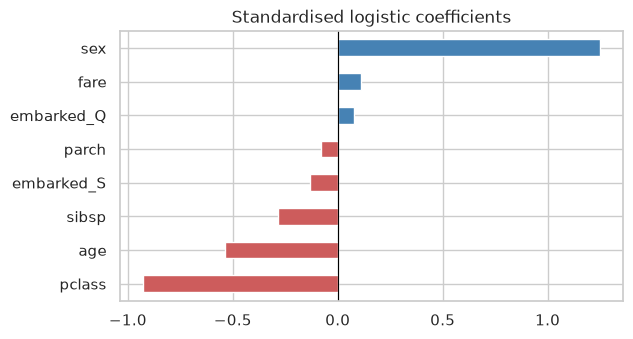

In [9]:
coef = pd.DataFrame({"coef (log-odds)": lr["model"].coef_[0]}, index=X.columns)
coef["odds ratio"] = np.exp(coef["coef (log-odds)"])
coef = coef.sort_values("coef (log-odds)", ascending=False)
display(coef)
coef["coef (log-odds)"].plot.barh(color=["steelblue" if v > 0 else "indianred" for v in coef["coef (log-odds)"]], figsize=(6.5, 3.5))
plt.axvline(0, color="black", linewidth=0.8); plt.title("Standardised logistic coefficients"); plt.gca().invert_yaxis(); plt.show()

Features are standardised, so coefficients are comparable. Positive means higher log-odds of survival; `odds ratio` is `e^coef` per +1 standard deviation.

- **Raises survival the most:** `sex` (female), +1.25 log-odds, odds ratio 3.5. Being female multiplies the odds of survival by about 3.5.
- **Lowers it the most:** `pclass` (-0.93, odds ratio 0.39: moving one standard deviation toward a lower class cuts the odds by about 60%), then `age` (-0.54, older is worse) and `sibsp` (-0.28, more siblings/spouses aboard is slightly worse).
- `fare`, `parch`, `embarked_*` are small (|coef| < 0.15) and not meaningful.

**Does it match the EDA?** Yes. Sex and class were the strongest patterns in 1.3 and are also the largest coefficients. Age also has the expected sign (children were prioritised). `fare` is slightly positive, but its effect is largely absorbed by `pclass`, since fare and class are strongly related (a collinearity effect, so I don't interpret it on its own).

---
## Stage 3: KNN and Decision Tree

### 3.1 KNN: choosing K

,train acc,CV acc (train only),test acc
K,,,
1,0.9859,0.7595,0.7528
3,0.8805,0.8031,0.7753
5,0.8636,0.8045,0.7978
7,0.8608,0.8101,0.8034
9,0.8453,0.8017,0.8202
11,0.8453,0.8102,0.8371
15,0.8354,0.8200,0.8202
21,0.8270,0.8087,0.7921
25,0.8242,0.8031,0.8146


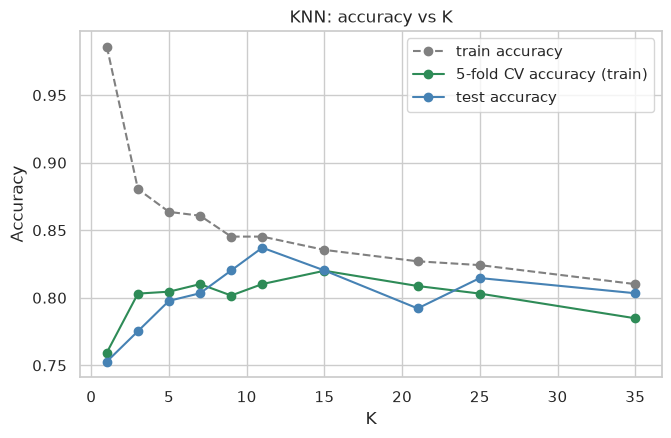

Best K by CV: 15 | best K by test accuracy: 11


In [10]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ks = [1, 3, 5, 7, 9, 11, 15, 21, 25, 35]
knn_rows = []
for k in ks:
    pipe = Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=k))])
    cv = cross_val_score(pipe, X_train, y_train, cv=skf, scoring="accuracy").mean()
    knn_rows.append({"K": k, "train acc": pipe.fit(X_train, y_train).score(X_train, y_train),
                     "CV acc (train only)": cv, "test acc": pipe.score(X_test, y_test)})
knn_df = pd.DataFrame(knn_rows).set_index("K")
display(knn_df)

plt.figure(figsize=(7.5, 4.5))
plt.plot(knn_df.index, knn_df["train acc"], "o--", label="train accuracy", color="gray")
plt.plot(knn_df.index, knn_df["CV acc (train only)"], "o-", label="5-fold CV accuracy (train)", color="seagreen")
plt.plot(knn_df.index, knn_df["test acc"], "o-", label="test accuracy", color="steelblue")
plt.xlabel("K"); plt.ylabel("Accuracy"); plt.title("KNN: accuracy vs K"); plt.legend(); plt.show()

best_k = int(knn_df["CV acc (train only)"].idxmax())
print("Best K by CV:", best_k, "| best K by test accuracy:", int(knn_df["test acc"].idxmax()))

**How I choose K:** The task asks for test accuracy vs K. Picking the K with the best *test* accuracy would tune on the data I use for the final report, which makes the result optimistic (best test K = 11 here, with a lucky 0.837). So I also compute a 5-fold stratified CV accuracy on the training set, and **choose K with CV: K = 15** (CV 0.820, test 0.820).

**Reading the curve (bias–variance):**
- **K = 1:** train accuracy 0.986 but CV 0.760 and test 0.753. The model memorises noise: low bias, high variance, **overfitting**.
- **K ≈ 7 to 15:** CV and test accuracy rise to 0.81–0.82 as averaging over more neighbours smooths the boundary.
- **K = 35:** train 0.810, CV 0.785: the neighbourhood is so wide that local structure is lost: high bias, **underfitting**.

The test curve is noisy (178 test passengers, one passenger is 0.56 percentage points), so differences of 1–2 points between nearby K values are not meaningful.

In [11]:
best_knn = Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=best_k))]).fit(X_train, y_train)

### 3.2 Decision Tree: `max_depth`

,train acc,CV acc (train only),test acc,gap (train - test)
max_depth,,,,
2,0.8031,0.7834,0.7640,0.0390
3,0.8256,0.8157,0.8146,0.0110
4,0.8411,0.8073,0.7978,0.0433
5,0.8565,0.8157,0.7697,0.0869
6,0.8776,0.7989,0.7584,0.1192
8,0.9142,0.7989,0.7584,0.1558
10,0.9437,0.7918,0.7640,0.1797
None,0.9859,0.7848,0.7528,0.2331


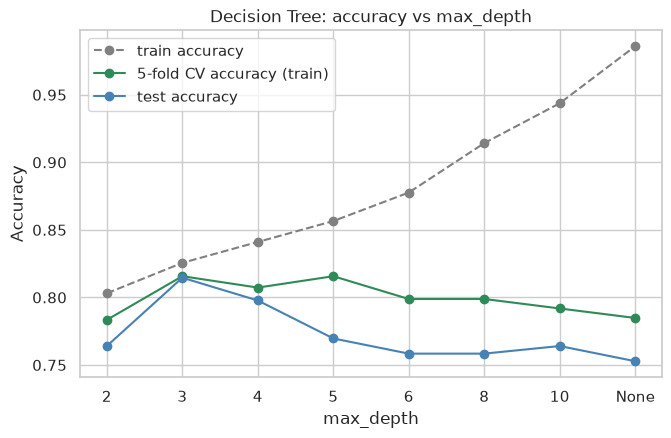

Best max_depth by CV: 3


In [12]:
depths = [2, 3, 4, 5, 6, 8, 10, None]
dt_rows = []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42)
    cv = cross_val_score(t, X_train, y_train, cv=skf, scoring="accuracy").mean()
    t.fit(X_train, y_train)
    dt_rows.append({"max_depth": str(d), "train acc": t.score(X_train, y_train),
                    "CV acc (train only)": cv, "test acc": t.score(X_test, y_test),
                    "gap (train - test)": t.score(X_train, y_train) - t.score(X_test, y_test)})
dt_df = pd.DataFrame(dt_rows).set_index("max_depth")
display(dt_df)

plt.figure(figsize=(7.5, 4.5))
x = range(len(dt_df))
plt.plot(x, dt_df["train acc"], "o--", color="gray", label="train accuracy")
plt.plot(x, dt_df["CV acc (train only)"], "o-", color="seagreen", label="5-fold CV accuracy (train)")
plt.plot(x, dt_df["test acc"], "o-", color="steelblue", label="test accuracy")
plt.xticks(x, dt_df.index); plt.xlabel("max_depth"); plt.ylabel("Accuracy")
plt.title("Decision Tree: accuracy vs max_depth"); plt.legend(); plt.show()

best_depth_s = dt_df["CV acc (train only)"].idxmax()
best_depth = None if best_depth_s == "None" else int(best_depth_s)
print("Best max_depth by CV:", best_depth_s)

| max_depth | train acc | test acc | gap |
|---|---|---|---|
| 2 | 0.803 | 0.764 | 0.039 |
| 4 | 0.841 | 0.798 | 0.043 |
| 6 | 0.878 | 0.758 | 0.119 |
| None | 0.986 | 0.753 | 0.233 |

**Where does overfitting start?** Train accuracy rises monotonically with depth (0.80 → 0.99), but CV and test accuracy peak at **depth 3** (CV 0.816, test 0.815) and then fall. The train–test gap passes 0.08 at depth 5 and keeps growing, reaching 0.23 for the unrestricted tree, which memorises the training set. So overfitting is visible from **depth 4 to 5** and clearly from depth 6. Depth 2 is too shallow (it underfits: low on all three numbers).

I choose **depth 3** using CV, consistent with the KNN choice. It is also the easiest to read as a flowchart.

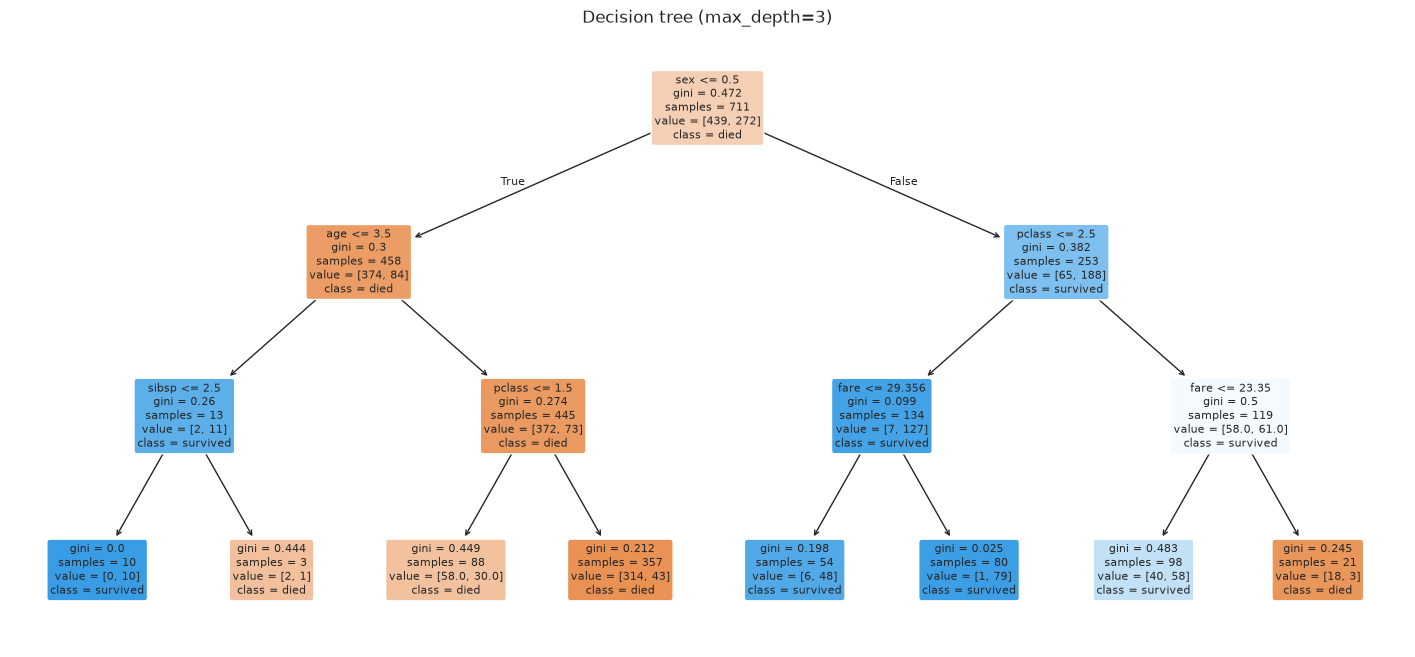

In [13]:
best_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42).fit(X_train, y_train)
plt.figure(figsize=(18, 8))
plot_tree(best_tree, feature_names=list(X.columns), class_names=["died", "survived"], filled=True, fontsize=8, rounded=True)
plt.title(f"Decision tree (max_depth={best_depth})"); plt.show()

### 3.3 Comparison table (test set)

In [14]:
models = {"Logistic Regression": lr, f"KNN (K={best_k})": best_knn, f"Decision Tree (depth={best_depth})": best_tree}
comp = pd.DataFrame([metrics_row(n, m) for n, m in models.items()]).set_index("model")
comp

,accuracy,precision,recall,f1,auc
model,,,,,
Logistic Regression,0.8258,0.8136,0.7059,0.7559,0.8592
KNN (K=15),0.8202,0.8333,0.6618,0.7377,0.8555
Decision Tree (depth=3),0.8146,0.8182,0.6618,0.7317,0.8614


All three models are close. Logistic Regression has the best accuracy (0.826), recall (0.706) and F1 (0.756). KNN has the highest precision (0.833), and the Decision Tree has the best AUC (0.861). With 178 test passengers, the differences (≈1 point of accuracy = 2 passengers) are inside the noise: Bonus 3 shows this with cross-validation.

---
## Stage 4: Deep Evaluation and Interpretation

### 4.1 ROC curves

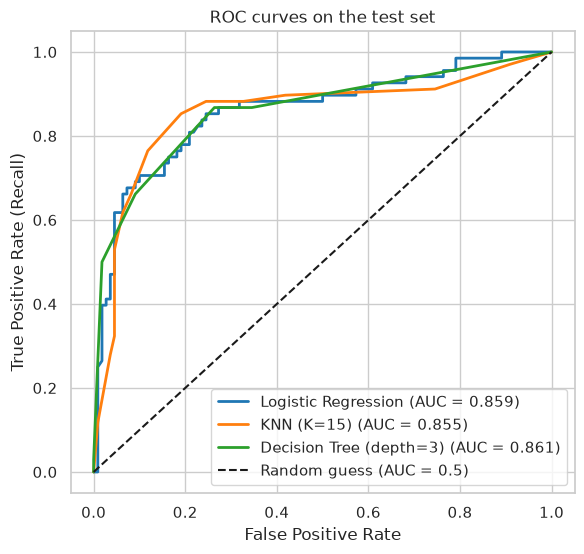

In [15]:
plt.figure(figsize=(6.5, 6))
for (name, m), c in zip(models.items(), ["tab:blue", "tab:orange", "tab:green"]):
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, color=c, linewidth=2, label=f"{name} (AUC = {roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (Recall)"); plt.title("ROC curves on the test set")
plt.legend(loc="lower right"); plt.show()

**Best threshold-independent performance:** the Decision Tree has the highest AUC (0.861), then Logistic Regression (0.859) and KNN (0.856). The gap is only 0.006, so in practice **the three are tied**; I would not claim one is better from this single test split. The curves also differ in shape: the tree's ROC has only a few distinct corners because depth 3 gives only about 8 leaves (so few distinct probability values), whereas Logistic Regression's curve is smooth, which makes its threshold fine-tunable (see Bonus 1).

### 4.2 Recommendation for the rescue-prioritisation scenario

In [16]:
# In this scenario the class we must NOT miss is "did not survive" (label 0): they need help.
# So treat 0 as the positive class: a false negative = a non-survivor predicted to survive.
rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()   # label 1 = positive here
    rows.append({"model": name,
                 "missed non-survivors (FN)": fp,            # actual 0, predicted 1
                 "unneeded help (FP)": fn,                   # actual 1, predicted 0
                 "recall (non-survivor)": recall_score(y_test, pred, pos_label=0),
                 "precision (non-survivor)": precision_score(y_test, pred, pos_label=0),
                 "F1 (non-survivor)": f1_score(y_test, pred, pos_label=0),
                 "accuracy": accuracy_score(y_test, pred)})
scenario = pd.DataFrame(rows).set_index("model")
scenario

,missed non-survivors (FN),unneeded help (FP),recall (non-survivor),precision (non-survivor),F1 (non-survivor),accuracy
model,,,,,,
Logistic Regression,11,20,0.9000,0.8319,0.8646,0.8258
KNN (K=15),9,23,0.9182,0.8145,0.8632,0.8202
Decision Tree (depth=3),10,23,0.9091,0.8130,0.8584,0.8146


**Reframing the problem:** here the passenger we must not miss is the one who **will not survive without help**, i.e. class 0 ("died"). So the right "positive" is class 0, and the costly error is a **false negative = a non-survivor the model predicted would survive**. The metric that measures this is **recall of class 0**. (Note that the recall reported in Stage 3.3 is for class 1, survivors, which is the wrong one for this scenario.)

| Model | Missed non-survivors | Recall (non-survivor) | Precision (non-survivor) | Unneeded help |
|---|---|---|---|---|
| Logistic Regression | 11 | 0.900 | 0.832 | 20 |
| KNN (K=15) | 9 | **0.918** | 0.815 | 23 |
| Decision Tree (depth 3) | 10 | 0.909 | 0.813 | 23 |

**Recommendation: KNN (K = 15).** It misses the fewest at-risk passengers (9 of 110, recall 91.8%), which is the metric that matters most here, at the cost of 3 extra unnecessary allocations compared with Logistic Regression (23 vs 20), a trade the scenario explicitly accepts.

**Caveats I want to be honest about:**
- The advantage is **2 passengers** over Logistic Regression and 1 over the tree on a 178-passenger test set. This is a weak signal, not proof. KNN also looks best in cross-validation (Bonus 3), which supports the choice, but the CV differences are inside one standard deviation too.
- Accuracy would have picked Logistic Regression (0.826), which shows why accuracy alone is the wrong guide here.
- If the team can use a probability threshold, **Logistic Regression is the more practical option**: it outputs smooth probabilities, so raising the cut-off for "will survive" trades precision for catching more at-risk passengers, and each lost point can be quantified (Bonus 1 shows the same mechanism for survivors).

### 4.3 Three insights for a museum curator

1. **Being a woman and travelling in a higher class were what mattered most.** About 3 in 4 women survived, but fewer than 1 in 5 men. Almost every first- and second-class woman lived (92–97%), while only about 1 in 7 third-class men did. The lifeboat order ("women and children first") was followed, but money and cabin location clearly shaped who got to a boat.
2. **Age and family size mattered too, but far less.** Younger passengers did better, and people travelling with several siblings or a spouse did slightly worse. The ticket price and the port of boarding added almost nothing once class was known.
3. **A simple model gets about 4 in 5 passengers right, but it will never be perfect.** Our models correctly predicted the fate of roughly 82% of the passengers they had not seen, using only a handful of facts. The remaining 18% are the personal stories, such as luck, location on the ship and decisions in the moment, which is a good reason for an exhibit to feature individual passengers and not only statistics.

---
## Bonus 1: Threshold tuning (Logistic Regression)

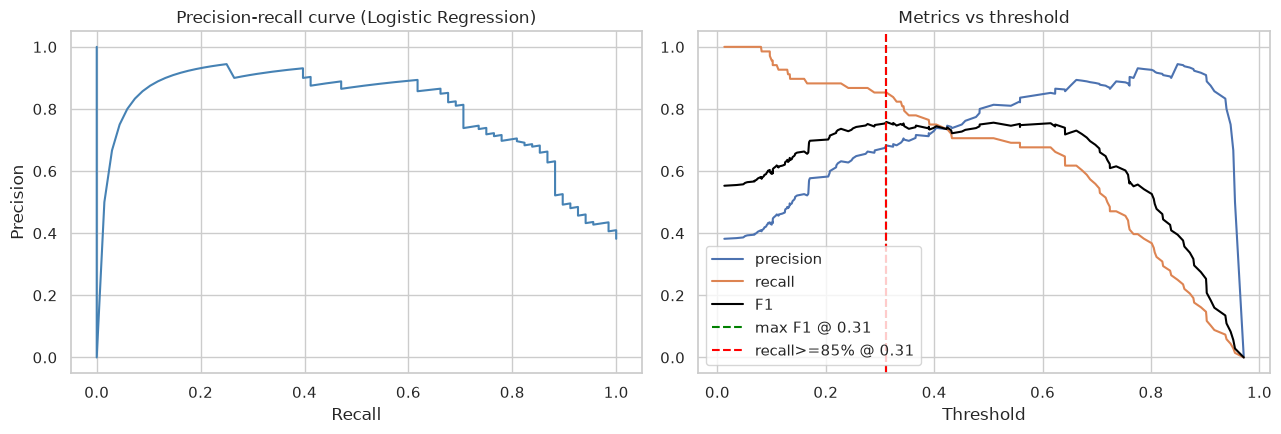

Max-F1 threshold: 0.312 (F1=0.758)
Lowest threshold with recall >= 85%: 0.013 (degenerate: close to 'predict everyone survived')
Highest threshold with recall >= 85%: 0.312


In [17]:
proba = lr.predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, proba)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
t_f1 = thr[np.argmax(f1s)]
ok = np.where(rec[:-1] >= 0.85)[0]
t_rec_low = thr[ok[0]]      # literally the lowest threshold with recall >= 85%
t_rec_high = thr[ok[-1]]    # the highest threshold that still keeps recall >= 85%

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(rec, prec, color="steelblue"); axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-recall curve (Logistic Regression)")
axes[1].plot(thr, prec[:-1], label="precision"); axes[1].plot(thr, rec[:-1], label="recall"); axes[1].plot(thr, f1s, label="F1", color="black")
axes[1].axvline(t_f1, color="green", ls="--", label=f"max F1 @ {t_f1:.2f}")
axes[1].axvline(t_rec_high, color="red", ls="--", label=f"recall>=85% @ {t_rec_high:.2f}")
axes[1].set_xlabel("Threshold"); axes[1].set_title("Metrics vs threshold"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Max-F1 threshold: {t_f1:.3f} (F1={f1s.max():.3f})")
print(f"Lowest threshold with recall >= 85%: {t_rec_low:.3f} (degenerate: close to 'predict everyone survived')")
print(f"Highest threshold with recall >= 85%: {t_rec_high:.3f}")

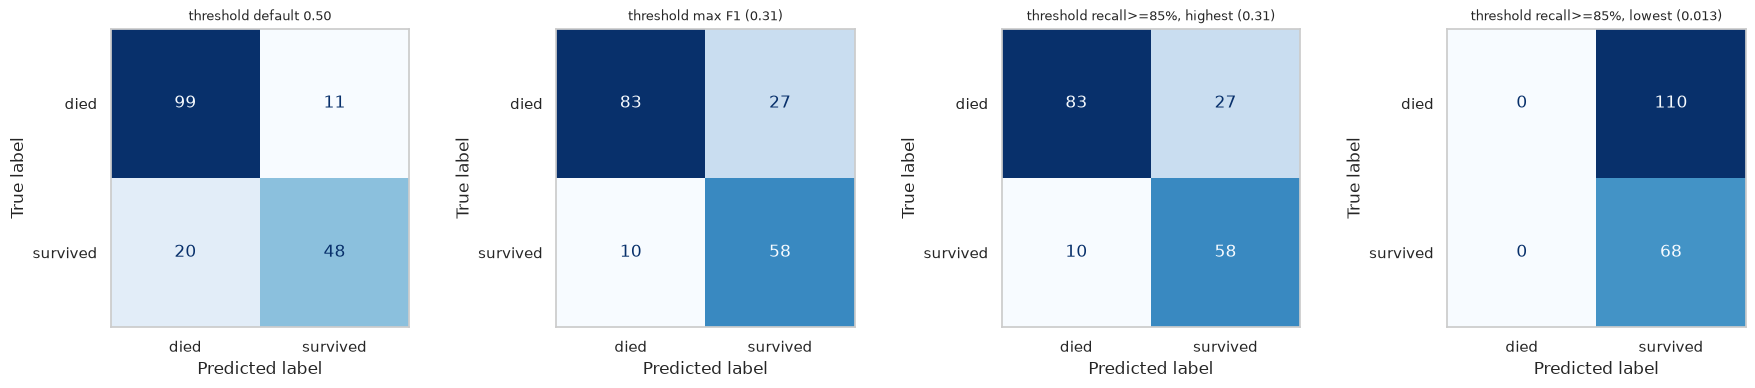

,precision,recall,F1,accuracy
threshold,,,,
default 0.50,0.8136,0.7059,0.7559,0.8258
max F1 (0.31),0.6824,0.8529,0.7582,0.7921
"recall>=85%, highest (0.31)",0.6824,0.8529,0.7582,0.7921
"recall>=85%, lowest (0.013)",0.3820,1.0000,0.5528,0.3820


In [18]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
summary = []
cases = [("default 0.50", 0.5), (f"max F1 ({t_f1:.2f})", t_f1),
         (f"recall>=85%, highest ({t_rec_high:.2f})", t_rec_high),
         (f"recall>=85%, lowest ({t_rec_low:.3f})", t_rec_low)]
for ax, (label, t) in zip(axes, cases):
    pred = (proba >= t).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["died", "survived"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"threshold {label}", fontsize=9); ax.grid(False)
    summary.append({"threshold": label, "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                    "F1": f1_score(y_test, pred), "accuracy": accuracy_score(y_test, pred)})
plt.tight_layout(); plt.show()
pd.DataFrame(summary).set_index("threshold")

**Results:**
- The F1 curve is quite flat, and the F1-maximising threshold is **0.31** (F1 0.758, barely above the 0.756 at the default).
- Recall is non-increasing in the threshold, so the *lowest* threshold with recall ≥ 85% is the degenerate answer (**0.013**): the model predicts almost everyone survives. I show its confusion matrix (4th panel) for completeness.
- The useful reading is the **highest** threshold that still keeps recall ≥ 85%, which is **0.31**. It coincides with the max-F1 threshold here, so the 2nd and 3rd matrices are identical.

| | threshold 0.50 | threshold 0.31 | threshold 0.013 (lowest) |
|---|---|---|---|
| precision | 0.814 | 0.682 | ≈ 0.38 (base rate) |
| recall | 0.706 | 0.853 | ≈ 1.00 |
| F1 | 0.756 | 0.758 | ≈ 0.55 |
| accuracy | 0.826 | 0.792 | ≈ 0.38 |

**Trade-off:** lowering the threshold from 0.50 to 0.31 raises recall of survivors from 71% to 85% (10 more survivors found), but precision drops from 81% to 68% (more false alarms) and accuracy falls by 3.4 points. F1 stays the same because it simply trades one for the other. Going all the way down to 0.013 gets recall to ~100% but the model is then no better than "everyone survives". The right threshold depends on the cost of each error, not on the metric itself: 0.31 is better when missing a survivor is worse than a false alarm, and 0.50 otherwise. (For the Stage 4.2 scenario, the direction is the opposite: we would *raise* the cut-off for predicting "survived".)

---
## Bonus 2: `ColumnTransformer` with one-hot `pclass`

In [19]:
raw = sns.load_dataset("titanic").drop(columns=["deck", "alive", "class", "embark_town", "who", "adult_male", "alone"])
raw = raw.dropna(subset=["embarked"]).reset_index(drop=True)
Xr, yr = raw.drop(columns="survived"), raw["survived"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42, stratify=yr)
assert (yr_test.index == y_test.index).all()    # same rows as the Stage 2 split

num_cols = ["age", "sibsp", "parch", "fare"]
cat_cols = ["sex", "embarked", "pclass"]
from sklearn.impute import SimpleImputer
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
lr_ohe = Pipeline([("pre", pre), ("model", LogisticRegression(max_iter=1000))]).fit(Xr_train, yr_train)

cmp2 = pd.DataFrame([metrics_row("Stage 2: pclass numeric", lr),
                     metrics_row("Bonus 2: pclass one-hot", lr_ohe, Xr_test, yr_test)]).set_index("model")
cmp2

,accuracy,precision,recall,f1,auc
model,,,,,
Stage 2: pclass numeric,0.8258,0.8136,0.7059,0.7559,0.8592
Bonus 2: pclass one-hot,0.8146,0.7966,0.6912,0.7402,0.8596


**Result:** the one-hot model scores accuracy 0.815 vs 0.826, F1 0.740 vs 0.756 and AUC 0.8596 vs 0.8592. AUC is identical to three decimals, and the accuracy and F1 differences are about 2 passengers out of 178, so **treating `pclass` as categorical does not change performance in a meaningful way.**

**Why:** `pclass` is ordinal, and the survival rate drops monotonically with it (62.6% → 47.3% → 24.2%), so a single numeric slope already captures most of the effect. One-hot encoding allows a different effect for each class (the 1→2 drop is smaller than the 2→3 drop, in log-odds about 0.6 vs 1.0) but the data are not rich enough for that extra flexibility to matter. With a more complex pattern (a non-monotonic effect) the categorical version would help.

One caution: this pipeline also imputes `age` with a simple global median inside the pipeline (instead of the median per class × sex used in Stage 1), so part of the small difference comes from the imputation and not only from the encoding.

---
## Bonus 3: Stratified cross-validation
I run 5-fold `StratifiedKFold` (shuffled, `random_state=42`) on the training set for the three Stage 3 models. Scoring is **F1** and **ROC-AUC** (and accuracy for reference): accuracy alone is misleading with a 62/38 split, F1 balances precision and recall for the survivor class, and AUC does not depend on a threshold.

CV is run on the **training set only** (711 rows), not on the full data: K and `max_depth` were already chosen with CV on it, and the test set stays untouched for the final report, so no test rows influence the CV scores.

In [20]:
cv_models = {"Logistic Regression": lr, f"KNN (K={best_k})": best_knn, f"Decision Tree (depth={best_depth})": best_tree}
cv_rows = []
for name, m in cv_models.items():
    f1 = cross_val_score(m, X_train, y_train, cv=skf, scoring="f1")
    auc = cross_val_score(m, X_train, y_train, cv=skf, scoring="roc_auc")
    acc = cross_val_score(m, X_train, y_train, cv=skf, scoring="accuracy")
    cv_rows.append({"model": name, "F1 mean": f1.mean(), "F1 std": f1.std(), "AUC mean": auc.mean(), "AUC std": auc.std(),
                    "Acc mean": acc.mean(), "Acc std": acc.std()})
cv_df = pd.DataFrame(cv_rows).set_index("model")
cv_df

,F1 mean,F1 std,AUC mean,AUC std,Acc mean,Acc std
model,,,,,,
Logistic Regression,0.7173,0.0583,0.8467,0.0367,0.7933,0.0418
KNN (K=15),0.7401,0.0402,0.8567,0.0318,0.8200,0.0298
Decision Tree (depth=3),0.7278,0.0495,0.8397,0.0211,0.8157,0.0307


| Model | F1 (mean ± std) | AUC (mean ± std) |
|---|---|---|
| Logistic Regression | 0.717 ± 0.058 | 0.847 ± 0.037 |
| KNN (K=15) | **0.740 ± 0.040** | **0.857 ± 0.032** |
| Decision Tree (depth 3) | 0.728 ± 0.050 | 0.840 ± 0.021 |

**Reading:** KNN has the best mean F1 and AUC, but the gaps between models (0.02) are **smaller than one standard deviation** (0.04–0.06), so the models cannot be separated reliably. Note that this ranking differs from the single test split in Stage 3.3, where Logistic Regression had the highest F1, which shows how much one 178-row split can mislead. Part of the KNN edge is also because K and depth were chosen with this same CV (a mild optimism for them), so it should not be read as a clear win.

**Why `StratifiedKFold` for classification:** plain `KFold` cuts the data into folds without looking at the labels, so by chance a fold can have a very different class ratio (more or fewer survivors). With a minority class, or small data, that makes fold scores noisy and, in extreme cases, a fold can contain almost none of the minority class so precision and recall are undefined or meaningless. `StratifiedKFold` keeps the 38/62 ratio in every fold, so each fold is representative, the scores have lower variance, and the comparison between models is fairer. It matters more as imbalance grows.

---
## Summary

| Model | Accuracy | Precision | Recall | F1 | AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.826 | 0.814 | 0.706 | 0.756 | 0.859 |
| KNN (K=15) | 0.820 | 0.833 | 0.662 | 0.738 | 0.856 |
| Decision Tree (depth 3) | 0.815 | 0.818 | 0.662 | 0.732 | 0.861 |

All three models land at about 82% accuracy and 0.86 AUC, and the differences are within noise. What drives the result is the data (sex, class, age), not the choice of algorithm. For the rescue scenario, where missing a non-survivor is the costly error, KNN has the highest recall of non-survivors (0.918), with Logistic Regression as the easier model to tune.